In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [ ]:
transform = transforms.ToTensor()

dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Split into training and validation data
train_data, val_data = torch.utils.data.random_split(
    dataset, [50000, 10000]
)

test_data = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = torch.utils.data.DataLoader(
    train_data, batch_size=64, shuffle=True
)

val_loader = torch.utils.data.DataLoader(
    val_data, batch_size=64, shuffle=False
)

test_loader = torch.utils.data.DataLoader(
    test_data, batch_size=64, shuffle=False
)

print("Dataset loaded successfully")

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 461kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.49MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.82MB/s]


Dataset loaded successfully


In [ ]:
class MLP(nn.Module):
    def __init__(self, dropout=False):
        super().__init__()

        layers = [
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU()
        ]

        # Add Dropout if enabled
        if dropout:
            layers.append(nn.Dropout(0.5))

        layers.extend([
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        ])

        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

In [ ]:
def train_model(dropout=False, l2=0, epochs=5):

    model = MLP(dropout)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=l2
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    for epoch in range(epochs):

        # Training
        model.train()
        total_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            predicted = outputs.argmax(dim=1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

        train_loss = total_loss / len(train_loader)
        train_acc = 100 * correct / total

        # Validation
        model.eval()
        val_loss = 0
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                predicted = outputs.argmax(dim=1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        val_loss = val_loss / len(val_loader)
        val_acc = 100 * correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_acc:.2f}%"
        )

    return model, history

In [ ]:
# Model 1: No regularization
model1, history1 = train_model(
    dropout=False,
    l2=0,
    epochs=5
)

# Model 2: L2 Regularization
model2, history2 = train_model(
    dropout=False,
    l2=0.001,
    epochs=5
)

# Model 3: Dropout
model3, history3 = train_model(
    dropout=True,
    l2=0,
    epochs=5
)

Epoch 1/5 | Train Loss: 0.3733 | Val Loss: 0.1808 | Val Accuracy: 94.74%
Epoch 2/5 | Train Loss: 0.1557 | Val Loss: 0.1265 | Val Accuracy: 96.28%
Epoch 3/5 | Train Loss: 0.1084 | Val Loss: 0.1134 | Val Accuracy: 96.66%
Epoch 4/5 | Train Loss: 0.0821 | Val Loss: 0.0869 | Val Accuracy: 97.31%
Epoch 5/5 | Train Loss: 0.0630 | Val Loss: 0.0875 | Val Accuracy: 97.28%
Epoch 1/5 | Train Loss: 0.3958 | Val Loss: 0.2137 | Val Accuracy: 93.64%
Epoch 2/5 | Train Loss: 0.1803 | Val Loss: 0.1427 | Val Accuracy: 95.91%
Epoch 3/5 | Train Loss: 0.1352 | Val Loss: 0.1309 | Val Accuracy: 96.26%
Epoch 4/5 | Train Loss: 0.1117 | Val Loss: 0.1098 | Val Accuracy: 96.80%
Epoch 5/5 | Train Loss: 0.0969 | Val Loss: 0.1020 | Val Accuracy: 97.13%
Epoch 1/5 | Train Loss: 0.5037 | Val Loss: 0.2075 | Val Accuracy: 93.65%
Epoch 2/5 | Train Loss: 0.2541 | Val Loss: 0.1488 | Val Accuracy: 95.50%
Epoch 3/5 | Train Loss: 0.2084 | Val Loss: 0.1262 | Val Accuracy: 96.25%
Epoch 4/5 | Train Loss: 0.1843 | Val Loss: 0.1146 |

In [ ]:
print("Without Regularization:",
      history1["val_acc"][-1], "%")

print("With L2 Regularization:",
      history2["val_acc"][-1], "%")

print("With Dropout:",
      history3["val_acc"][-1], "%")

Without Regularization: 97.28 %
With L2 Regularization: 97.13 %
With Dropout: 96.86 %


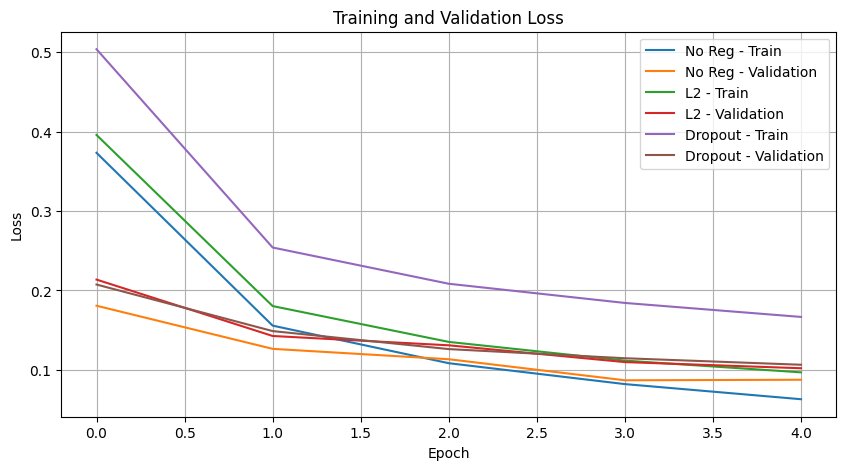

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history1["train_loss"], label="No Reg - Train")
plt.plot(history1["val_loss"], label="No Reg - Validation")

plt.plot(history2["train_loss"], label="L2 - Train")
plt.plot(history2["val_loss"], label="L2 - Validation")

plt.plot(history3["train_loss"], label="Dropout - Train")
plt.plot(history3["val_loss"], label="Dropout - Validation")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

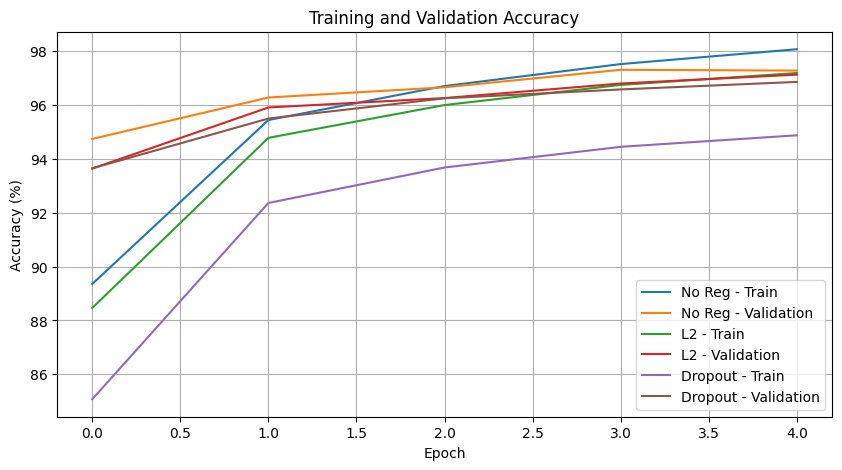

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history1["train_acc"], label="No Reg - Train")
plt.plot(history1["val_acc"], label="No Reg - Validation")

plt.plot(history2["train_acc"], label="L2 - Train")
plt.plot(history2["val_acc"], label="L2 - Validation")

plt.plot(history3["train_acc"], label="Dropout - Train")
plt.plot(history3["val_acc"], label="Dropout - Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

In [ ]:
def test_model(model):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images)
            predicted = outputs.argmax(dim=1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


print("Test Accuracy Without Regularization:",
      test_model(model1), "%")

print("Test Accuracy with L2:",
      test_model(model2), "%")

print("Test Accuracy with Dropout:",
      test_model(model3), "%")

Test Accuracy Without Regularization: 97.38 %
Test Accuracy with L2: 97.13 %
Test Accuracy with Dropout: 96.93 %
